In [18]:
# Load basic libraries
import os, json, re, operator, duckdb
from dotenv import load_dotenv
import pandas as pd
from pydantic import BaseModel, Field
from typing import TypedDict, Annotated
from langchain_openai import ChatOpenAI
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from IPython.display import Image

# Load and setup environent vriables
load_dotenv(".env")
model_sql = ChatOpenAI(api_key=os.getenv("API_KEY"),model='gpt-4o-mini',temperature=0)

In [19]:
parientData = pd.read_csv('patient_data.csv')
parientData['last_visit_date'] = pd.to_datetime(parientData['last_visit_date'])
parientData['next_scheduled_visit'] = pd.to_datetime(parientData['next_scheduled_visit'])

parientData['last_visit_date_weekday'] = parientData['last_visit_date'].dt.day_name()
parientData['next_scheduled_visit_weekday'] = parientData['next_scheduled_visit'].dt.day_name()

parientData['age_group'] = pd.cut(parientData["age"],bins=[0, 17, 34, 49, 64, 120],labels=["0-17", "18-34", "35-49", "50-64", "65+"])
parientData.head()

,patient_id,patient_name,age,gender,diagnosis,current_medication,lab_test,lab_value,lab_unit,last_visit_date,...,days_since_last_visit,missed_last_appointment,vitals_bp_systolic,vitals_bp_diastolic,vitals_heart_rate,vitals_spo2,notes,last_visit_date_weekday,next_scheduled_visit_weekday,age_group
0,P0001,Aarav Sharma,68,Male,Type 2 Diabetes,Metformin 500mg,HbA1c,9.9,%,2024-04-24,...,251,No,174,70,95,96,Patient reports good medication adherence.,Wednesday,Saturday,65+
1,P0002,Priya Patel,29,Male,Heart Failure,Furosemide 40mg,BNP,317.6,pg/mL,2024-01-14,...,352,No,174,91,72,97,Patient reports no new symptoms.,Sunday,Wednesday,18-34
2,P0003,Rohan Mehta,45,Male,"Type 2 Diabetes, CKD","Insulin Glargine 10U, Losartan 50mg",HbA1c,11.4,%,2024-08-04,...,149,No,132,86,64,91,Medication dose adjusted this visit.,Sunday,Thursday,35-49
3,P0004,Anjali Singh,34,Female,"COPD, Heart Failure","Tiotropium 18mcg, Furosemide 40mg",FEV1%,33.8,%,2024-01-23,...,343,No,153,70,93,94,Patient reports no new symptoms.,Tuesday,Monday,18-34
4,P0005,Vikram Nair,51,Male,"Hypertension, Heart Failure","Amlodipine 5mg, Furosemide 40mg",BP Systolic,124.9,mmHg,2024-04-26,...,249,No,134,71,82,94,Patient education provided on diet and lifestyle.,Friday,Tuesday,50-64


In [20]:
def task_1(question: str) -> dict:
    query_con = duckdb.connect(":memory:")
    query_con.register("patients", parientData)
    schema = query_con.execute("DESCRIBE patients").df().to_string(index=False)

    sql_response = model_sql.invoke([
        SystemMessage(content=f"""
            Generate one read-only DuckDB SQL query for the patients table.
            Schema: {schema}
            Rules:
            - Return SQL only, no explanations or Markdown.
            - Start with SELECT or WITH.
            - Use only existing columns and valid DuckDB syntax.
            - Never modify data.
            - `missed_last_appointment` is a timestamp flag, not appointment history.
            - If the question cannot be answered from the schema, return a SELECT query explaining the limitation.
            """),
        HumanMessage(content=question)
    ])
    sql_query = sql_response.content.strip().removeprefix("```sql").removesuffix("```").strip()

    results = query_con.execute(sql_query).df().to_dict(orient="records")
    query_con.close()
    answer_response = model_sql.invoke([
        SystemMessage(content="Answer concisely using only the SQL results. Do not invent findings."),
        HumanMessage(content=f"Question: {question}\nResults: {json.dumps(results, default=str)}")
        ])
    
    total_token = answer_response.usage_metadata.get("total_tokens") + sql_response.usage_metadata.get("total_tokens")
    print(f"---------Total Tokens used:- {total_token}, sql:- {sql_response.usage_metadata.get("total_tokens")} llm:- {answer_response.usage_metadata.get("total_tokens")}")
    return {
        "sql_query": sql_query,
        "results": results,
        "answer": answer_response.content
    }

In [21]:
# Testing Task 1
response = task_1("which diagnosis has the highest missed appointment percentage?")
print(response["answer"])

---------Total Tokens used:- 591, sql:- 511 llm:- 80
The diagnosis with the highest missed appointment percentage is Hypertension, with a percentage of 40.0%.


In [22]:
# Task 2
@tool
def get_patient_data(patient_id: str) -> dict:
    """Retrieve a patient's complete record using their patient ID."""
    print("-----TOOL-----get_patient_data")
    patient = parientData[parientData["patient_id"] == patient_id]
    if patient.empty:
        return {"error": "Patient not found"}
    return patient.iloc[0].to_dict()

@tool
def get_missed_appointment_patients() -> list:
    """Retrieve patients marked as having missed their last appointment."""
    print("-----TOOL-----get_missed_appointment_patients")
    patients = parientData[parientData["missed_last_appointment"] == "Yes"][['patient_id', 'patient_name', 'age', 'gender', 'diagnosis','current_medication','notes']]
    return patients.to_dict(orient="records")

@tool
def get_patient_followup_context(patient_id: str) -> dict:
    """Get follow-up relevant details for a patient, including diagnosis,
    medication, lab results, notes, and next scheduled visit."""
    print("-----TOOL-----get_patient_followup_context")
    patient = get_patient_data.invoke({"patient_id": patient_id})
    if "error" in patient:
        return patient
    fields = [
        "patient_id", "patient_name", "diagnosis",
        "current_medication", "lab_test", "lab_value",
        "lab_unit", "last_visit_date", "next_scheduled_visit",
        "days_since_last_visit", "missed_last_appointment",
        "vitals", "notes"
    ]
    return {key: patient.get(key) for key in fields}

@tool
def filter_patient_diagnosis_data(diagnoses: list[str], question: str) -> dict:
    """Find patient IDs matching for one or more diagnoses use for requests. Include appointment/age/gender/name-related fields only when the question is related to these."""
    print("-----TOOL-----filter_patient_data")
    cols = ['patient_id', 'diagnosis']
    filtered = parientData[parientData["diagnosis"].str.contains("|".join(diagnoses),case=False,na=False,regex=True)]
    appointment_keywords = ["appointment","missed visit","missed appointment","last visit","next visit","scheduled visit","visit date","follow-up","follow up"]
    age_gender_keywords = ['age', 'gender', 'sex', 'year', 'years', 'old']
    is_appointment_related = any(keyword in question.lower() for keyword in appointment_keywords)
    is_age_gender_related = any(keyword in question.lower() for keyword in age_gender_keywords)
    if is_appointment_related:
        cols.extend(["missed_last_appointment", "last_visit_date", "next_scheduled_visit"])
    if is_age_gender_related:
            cols.extend(['age', 'gender','patient_name'])
    filtered = filtered[cols]
    return filtered.to_dict(orient="records")

@tool
def analyze_dataset(question: str) -> dict:
    """this tool is used for EDA with DuckDB SQL query in the database."""
    print("-----TOOL-----EDA ")
    return task_1(question)
tools = [get_patient_data,get_missed_appointment_patients,get_patient_followup_context,analyze_dataset,filter_patient_diagnosis_data]

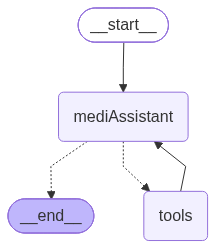

In [23]:
class MedicareState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
llm_with_tools = model_sql.bind_tools(tools)

def mediAssistant(state: MedicareState):
    response = llm_with_tools.invoke([
        SystemMessage(content="""
        you are a agent at MediCare and your task is to do data analysis assistant.

        Decide what to do for each user message:

        - General questions: answer directly without tools.
        - Dataset-wide EDA, counts, statistics, comparisons, trends, and diagnosis analysis across patients: use analyze_dataset.
        - Individual patient queries: use get_patient_data.
        - Patient follow-up questions and suggestions: use get_patient_followup_context and provide practical, data-based guidance.
        - Missed appointment queries: use get_missed_appointment_patients.
        - Patient filtering requests on the basis of diagnosis: use filter_patient_diagnosis_data.
        - Follow-up questions: use conversation history to understand context.
        - Ambiguous requests: ask for clarification.
        - Call multiple tools when necessary and summarize their results.

        Response rules:
        - Use tool results as evidence; never invent patient data, diagnoses, or historical appointment counts.
        - Provide specific, actionable follow-up suggestions based on recorded patient data.
        - Do not replace answers with generic disclaimers or refuse routine follow-up assistance.
        - Do not diagnose conditions or prescribe medications.
        - Keep responses concise and structured, with each item on a new line, reply only whats needed and save tokens.
        """),
        *state["messages"]
    ])
    print(f"---------Total Tokens used:- {response.usage_metadata.get('total_tokens')}")
    return {"messages": [response]}


def route_request(state: MedicareState):
    if state["messages"][-1].tool_calls:
        return "tools"
    return END


graph = StateGraph(MedicareState)

graph.add_node("mediAssistant", mediAssistant)
graph.add_node("tools", ToolNode(tools))

graph.add_edge(START, "mediAssistant")
graph.add_conditional_edges("mediAssistant",route_request,{"tools": "tools", END: END})
graph.add_edge("tools", "mediAssistant")

workflow = graph.compile()
Image(workflow.get_graph().draw_mermaid_png())

In [24]:
chat_history = []

def chat(user_message: str):
    global chat_history

    chat_history.append(HumanMessage(content=user_message))

    result = workflow.invoke({"messages": chat_history})

    chat_history = result["messages"]

    return chat_history[-1].content

In [25]:
# Testing Task 1 / task 2/ task 3
print(chat("Analyze the dataset, tell me on which day of the week a customer is more likly to miss an appointment?"))

---------Total Tokens used:- 506
-----TOOL-----EDA 
---------Total Tokens used:- 579, sql:- 507 llm:- 72
---------Total Tokens used:- 617
Patients most frequently miss their appointments on **Friday**.


In [26]:
print(chat("which diagnosis has the highest missed appointment percentage?"))

---------Total Tokens used:- 657
-----TOOL-----EDA 
---------Total Tokens used:- 647, sql:- 548 llm:- 99
---------Total Tokens used:- 858
The diagnosis with the highest percentage of missed appointments is **Hypertension**, with a percentage of **40.0%**.


In [27]:
# getting detials of a patient from task 4 - Single Patient Analysis 
print(chat("Now show me patient P0003's details."))

---------Total Tokens used:- 893
-----TOOL-----get_patient_data
---------Total Tokens used:- 1311
Here are the details for patient **P0003** (Rohan Mehta):

- **Age:** 45
- **Gender:** Male
- **Diagnosis:** Type 2 Diabetes, CKD
- **Current Medication:** Insulin Glargine 10U, Losartan 50mg
- **Lab Test:** HbA1c
- **Lab Value:** 11.4% 
- **Last Visit Date:** August 4, 2024 (Sunday)
- **Next Scheduled Visit:** October 3, 2024 (Thursday)
- **Days Since Last Visit:** 149
- **Missed Last Appointment:** No
- **Vitals:**
  - Blood Pressure: 132/86
  - Heart Rate: 64
  - SpO2: 91%
- **Notes:** Medication dose adjusted this visit.


In [28]:
print(chat("What follow-up would you suggest for this patient?"))

---------Total Tokens used:- 1348
-----TOOL-----get_patient_followup_context
-----TOOL-----get_patient_data
---------Total Tokens used:- 1681
For patient **P0003** (Rohan Mehta), I suggest the following follow-up actions:

- **Monitor HbA1c Levels:** Given the lab value of **11.4%**, it's important to closely monitor blood sugar levels and consider adjustments to the diabetes management plan.
- **Medication Review:** Since the medication dose was adjusted during the last visit, ensure adherence to the new regimen and assess its effectiveness at the next appointment.
- **Next Scheduled Visit:** Encourage attendance at the next scheduled visit on **October 3, 2024**, to evaluate progress and make any necessary changes.
- **Lifestyle Modifications:** Discuss dietary changes and physical activity to help manage diabetes and CKD effectively.
- **Regular Monitoring:** Recommend regular blood pressure and blood sugar monitoring at home to track any changes before the next visit.


In [29]:
print(chat("give patient id where Missed Last Appointment is yes"))

---------Total Tokens used:- 1713
-----TOOL-----get_missed_appointment_patients
---------Total Tokens used:- 2992
Here are the patient IDs where the last appointment was missed:

- **P0018** - Lakshmi Menon (Heart Failure)
- **P0031** - Harish Bajaj (Chronic Kidney Disease)
- **P0036** - Vandana Srivastava (Type 2 Diabetes)
- **P0041** - Tarun Mukherjee (Hypertension)
- **P0043** - Gaurav Dey (Hypertension, Anemia)
- **P0058** - Hina Akhtar (Heart Failure)
- **P0062** - Mary Joseph (Asthma)
- **P0063** - John Fernandez (Hypertension)
- **P0066** - Angela Pereira (Type 2 Diabetes, CKD)
- **P0069** - Victor Lobo (Type 2 Diabetes)
- **P0070** - Teresa Dias (Osteoarthritis)
- **P0076** - Parmjit Hundal (Depression)
- **P0081** - Nandini Rao (Hypothyroidism)
- **P0098** - Mrinal Basu (Heart Failure)
- **P0099** - Paramita Chatterjee (Type 2 Diabetes, Hypertension)


In [30]:
print(chat("Now show me patient P0018's details."))

---------Total Tokens used:- 3027
-----TOOL-----get_patient_data
---------Total Tokens used:- 3425
Here are the details for patient **P0018** (Lakshmi Menon):

- **Age:** 36
- **Gender:** Female
- **Diagnosis:** Heart Failure
- **Current Medication:** Furosemide 40mg
- **Lab Test:** BNP
- **Lab Value:** 952.3 pg/mL
- **Last Visit Date:** July 27, 2024 (Saturday)
- **Next Scheduled Visit:** September 10, 2024 (Tuesday)
- **Days Since Last Visit:** 157
- **Missed Last Appointment:** Yes
- **Vitals:**
  - Blood Pressure: 160/87
  - Heart Rate: 85
  - SpO2: 96%
- **Notes:** Patient education provided on diet and lifestyle.


In [31]:
print(chat("What follow-up would you suggest for this patient?"))

---------Total Tokens used:- 3462
-----TOOL-----get_patient_followup_context
-----TOOL-----get_patient_data
---------Total Tokens used:- 3814
For patient **P0018** (Lakshmi Menon), I suggest the following follow-up actions:

- **Monitor BNP Levels:** Given the lab value of **952.3 pg/mL**, it's important to monitor heart failure status closely. Consider repeating the BNP test at the next visit.
- **Medication Adherence:** Reinforce the importance of taking **Furosemide 40mg** as prescribed and discuss any side effects or concerns regarding the medication.
- **Next Scheduled Visit:** Encourage attendance at the next scheduled visit on **September 10, 2024**, to assess heart failure management and adjust treatment if necessary.
- **Lifestyle Modifications:** Continue to provide education on diet and lifestyle changes that can help manage heart failure, such as sodium restriction and fluid management.
- **Symptom Monitoring:** Advise the patient to monitor for any worsening symptoms, such

In [32]:
print(chat("prepare a small follow-up care message to be sent to this patient mentioning next scheduled visit"))

---------Total Tokens used:- 3945
Dear Lakshmi Menon,

We hope this message finds you well. This is a reminder for your next scheduled visit on **September 10, 2024**. During this appointment, we will assess your heart failure management and discuss any concerns you may have.

Please remember to continue taking your medication (Furosemide 40mg) as prescribed and monitor any symptoms. If you experience any worsening symptoms, do not hesitate to reach out.

Looking forward to seeing you soon!

Best regards,  
[Your Healthcare Team]


In [33]:
print(chat("find all patient id's with any of these Type 2 Diabetes, Hypertension, Heart Failure, COPD, and Anemia"))

---------Total Tokens used:- 4025
-----TOOL-----filter_patient_data
---------Total Tokens used:- 6084
Here are the patient IDs with any of the diagnoses: Type 2 Diabetes, Hypertension, Heart Failure, COPD, and Anemia:

- **P0001** - Type 2 Diabetes
- **P0002** - Heart Failure
- **P0003** - Type 2 Diabetes, CKD
- **P0004** - COPD, Heart Failure
- **P0005** - Hypertension, Heart Failure
- **P0007** - COPD
- **P0008** - Heart Failure
- **P0009** - Hypertension, Heart Failure
- **P0010** - Type 2 Diabetes, CKD
- **P0014** - Heart Failure
- **P0016** - Hypertension
- **P0017** - Heart Failure
- **P0018** - Heart Failure
- **P0019** - Type 2 Diabetes, Hypertension
- **P0021** - Hypertension
- **P0022** - Anemia
- **P0023** - Heart Failure
- **P0024** - Type 2 Diabetes
- **P0029** - Hypertension, Anemia
- **P0030** - COPD
- **P0032** - Anemia
- **P0034** - COPD
- **P0035** - Heart Failure
- **P0036** - Type 2 Diabetes
- **P0037** - Anemia
- **P0038** - Type 2 Diabetes, Hypertension
- **P0040*

In [34]:
print(chat("please share me these id's where Missed Last Appointment is Yes"))

---------Total Tokens used:- 6184
-----TOOL-----get_missed_appointment_patients
-----TOOL-----filter_patient_data
---------Total Tokens used:- 8607
Here are the patient IDs with any of the specified diagnoses (Type 2 Diabetes, Hypertension, Heart Failure, COPD, Anemia) where the last appointment was missed:

- **P0018** - Lakshmi Menon (Heart Failure)
- **P0036** - Vandana Srivastava (Type 2 Diabetes)
- **P0043** - Gaurav Dey (Hypertension, Anemia)
- **P0058** - Hina Akhtar (Heart Failure)
- **P0029** - Hypertension, Anemia
- **P0073** - Hypertension, Anemia
- **P0090** - Hypertension, Anemia
- **P0097** - Hypertension, Anemia
